In [1]:
import pandas as pd 

In [7]:
df=pd.read_csv("../data/customer_churn.csv")

In [8]:
print(df.shape)

(7043, 21)


In [10]:
print(df['Churn'].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [11]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [14]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [17]:
blank=df[df['TotalCharges'].str.strip()==""]
print(len(blank))

11


In [18]:
blank[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [19]:
# 1. Convert TotalCharges from text to numbers.
#    errors="coerce" turns anything that can't be converted (the blank spaces) into NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# 2. Fill those NaN values with 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# 3. Convert the target to numbers: Yes -> 1, No -> 0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# 4. Drop the ID column (no predictive value)
df = df.drop(columns=['customerID'])

In [21]:
print(df.shape)                    
print(df['TotalCharges'].dtype)      
print(df.isnull().sum().sum())     
print(df['Churn'].mean()) 

(7043, 20)
float64
0
0.2653698707936959


In [23]:
print(df['MultipleLines'].value_counts())
print(df['OnlineSecurity'].value_counts())

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64


In [25]:
for c in df.columns:
    print(df[c].value_counts())
    print("-" * 30)

gender
Male      3555
Female    3488
Name: count, dtype: int64
------------------------------
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64
------------------------------
Partner
No     3641
Yes    3402
Name: count, dtype: int64
------------------------------
Dependents
No     4933
Yes    2110
Name: count, dtype: int64
------------------------------
tenure
1     613
72    362
2     238
3     200
4     176
     ... 
28     57
39     56
44     51
36     50
0      11
Name: count, Length: 73, dtype: int64
------------------------------
PhoneService
Yes    6361
No      682
Name: count, dtype: int64
------------------------------
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
------------------------------
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
------------------------------
OnlineSecurity
No                     3498
Yes                    2019
No i

In [26]:
# "No internet service" / "No phone service" carry no new information: whether a
# customer has internet or phone is already recorded in InternetService and
# PhoneService. So we merge them into "No" to keep each column simple (Yes/No).
cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
        'TechSupport', 'StreamingTV', 'StreamingMovies']

for c in cols:
    df[c] = df[c].replace('No internet service', 'No')

df['MultipleLines'] = df['MultipleLines'].replace('No phone service', 'No')

In [27]:
cat_cols = ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport',
            'OnlineSecurity', 'PaperlessBilling', 'SeniorCitizen',
            'Partner', 'Dependents', 'gender']

for c in cat_cols:
    print(df.groupby(c)['Churn'].mean().round(3).sort_values(ascending=False))
    print("-" * 30)
#Why: the overall churn rate is 26.5%. If one group churns at 42% and another at 3%, that feature clearly separates the two outcomes and will help the model.

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64
------------------------------
InternetService
Fiber optic    0.419
DSL            0.190
No             0.074
Name: Churn, dtype: float64
------------------------------
PaymentMethod
Electronic check             0.453
Mailed check                 0.191
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Name: Churn, dtype: float64
------------------------------
TechSupport
No     0.312
Yes    0.152
Name: Churn, dtype: float64
------------------------------
OnlineSecurity
No     0.313
Yes    0.146
Name: Churn, dtype: float64
------------------------------
PaperlessBilling
Yes    0.336
No     0.163
Name: Churn, dtype: float64
------------------------------
SeniorCitizen
1    0.417
0    0.236
Name: Churn, dtype: float64
------------------------------
Partner
No     0.330
Yes    0.197
Name: Churn, dtype: float64
------------------------------
Dependents
No     0.31

from the above cell we can observe that -Top churn drivers (highest → lowest):
  - Contract: Month-to-month (42.7%) vs Two-year (2.8%)
  - InternetService: Fiber optic (41.9%) vs DSL (19.0%) vs No (7.4%)
  - PaymentMethod: Electronic check (45.3%) vs Credit card (15.2%)
  - TechSupport: No (31.2%) vs Yes (15.2%)
  - OnlineSecurity: No (31.3%) vs Yes (14.6%)
  - PaperlessBilling: Yes (33.6%) vs No (16.3%)
  - SeniorCitizen: Yes (41.7%) vs No (23.6%)
  - Partner and Dependents:  Customers without a partner (33.0% vs 19.7%) or dependents (31.3% vs 15.5%) churn more, which is a real pattern.

In [28]:
print(df.groupby('Churn')[['tenure', 'MonthlyCharges', 'TotalCharges']].mean().round(1))

       tenure  MonthlyCharges  TotalCharges
Churn                                      
0        37.6            61.3        2549.9
1        18.0            74.4        1531.8


- Tenure — Non-churners stay about 2× longer (37.6 vs 18 months). This is the strongest protective signal.
- MonthlyCharges — Churners pay ~21% more per month ($74.4 vs $61.3). Higher monthly cost drives churn.
- TotalCharges — Despite lower monthly rates, non-churners generate ~66% more lifetime revenue ($2,550 vs $1,532) because they stay longer.

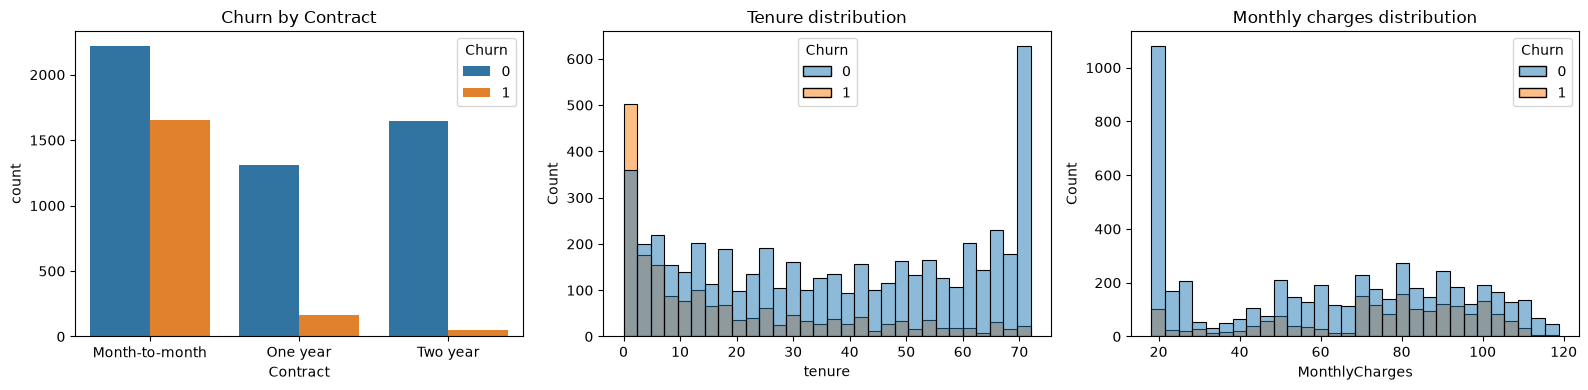

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(x='Contract', hue='Churn', data=df, ax=axes[0])
axes[0].set_title('Churn by Contract')

sns.histplot(data=df, x='tenure', hue='Churn', bins=30, ax=axes[1])
axes[1].set_title('Tenure distribution')

sns.histplot(data=df, x='MonthlyCharges', hue='Churn', bins=30, ax=axes[2])
axes[2].set_title('Monthly charges distribution')

plt.tight_layout()
plt.show()

Customers on month-to-month contracts are the most likely to leave. One-year customers rarely leave, and two-year customers almost never do.

from the tenure distribution we can see people with the least time in the company are more likely to leave the company 

In [30]:
#just checking before train test split 
print(df.shape)                    # expect (7043, 20)
print(df.isnull().sum().sum())     # expect 0
print(df['TotalCharges'].dtype)    # expect float64
print(df['Churn'].unique())        # expect [0 1]
for c in ['MultipleLines','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']:
    print(c, df[c].unique())       # expect only Yes/No

(7043, 20)
0
float64
[0 1]
MultipleLines <StringArray>
['No', 'Yes']
Length: 2, dtype: str
OnlineSecurity <StringArray>
['No', 'Yes']
Length: 2, dtype: str
OnlineBackup <StringArray>
['Yes', 'No']
Length: 2, dtype: str
DeviceProtection <StringArray>
['No', 'Yes']
Length: 2, dtype: str
TechSupport <StringArray>
['No', 'Yes']
Length: 2, dtype: str
StreamingTV <StringArray>
['No', 'Yes']
Length: 2, dtype: str
StreamingMovies <StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [31]:
print(df.duplicated().sum())#duplicates check 22 is ok 

22


In [32]:
print(df[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']].corr().round(2))

                tenure  MonthlyCharges  TotalCharges  Churn
tenure            1.00            0.25          0.83  -0.35
MonthlyCharges    0.25            1.00          0.65   0.19
TotalCharges      0.83            0.65          1.00  -0.20
Churn            -0.35            0.19         -0.20   1.00


In [33]:
print(df[['tenure', 'MonthlyCharges', 'TotalCharges']].describe().round(1))

       tenure  MonthlyCharges  TotalCharges
count  7043.0          7043.0        7043.0
mean     32.4            64.8        2279.7
std      24.6            30.1        2266.8
min       0.0            18.2           0.0
25%       9.0            35.5         398.6
50%      29.0            70.4        1394.6
75%      55.0            89.8        3786.6
max      72.0           118.8        8684.8


In [34]:
   df = df.drop(columns=['gender'])

In [35]:
df

,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,0,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,0
7039,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,0
7040,0,Yes,Yes,11,No,No,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,0
7041,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,1


In [36]:
df.to_csv("../data/churn_clean.csv", index=False)